# EDA — TP2 | Customer Support Ticket Dataset

**Objetivo:** realizar uma análise exploratória completa do conjunto de chamados de suporte, incluindo variáveis numéricas, categóricas, temporais e texto livre. Este notebook complementa o EDA do TP1 sem substituí-lo.

**Dataset:** `data/customer_support_tickets.csv` (8.469 registros, 17 colunas na versão fornecida no projeto). A documentação do projeto descreve o conjunto como sintético, disponibilizado no Kaggle por Suraj Jha sob licença CC0 1.0.

## Roteiro

1.1. Compreensão do problema e do dataset; 1.2. Inspeção inicial; 1.3. Qualidade dos dados; 1.4. Limpeza e preparação; 1.5. Análise univariada; 1.6. Análise multivariada e testes de hipótese; 1.7. Outliers e anomalias; 1.8. Documentação e conclusões.

> **Nota metodológica:** os testes estatísticos serão executados nos dados disponíveis e acompanhados do tamanho dos grupos, estatística U, *p*-valor e tamanho de efeito. Um resultado não significativo significa que não há evidência suficiente para rejeitar a hipótese nula a 5%; não prova que os grupos sejam idênticos.

## 1.1. Compreensão do problema e do dataset

O conjunto representa chamados de atendimento ao cliente. A variável `Ticket Type` possui cinco classes (`Billing inquiry`, `Cancellation request`, `Product inquiry`, `Refund request` e `Technical issue`) e pode ser tratada como rótulo de intenção em um problema futuro de classificação de texto.

A EDA procura responder:

- Como estão distribuídas as variáveis numéricas e categóricas?
- Há dados ausentes, duplicados, valores fora do domínio ou inconsistências temporais?
- Que padrões aparecem no comprimento e no conteúdo das descrições?
- Existem diferenças estatisticamente detectáveis na satisfação conforme a prioridade e no comprimento do texto conforme o tipo de chamado?

**Limites de interpretação:** o dataset é sintético. Associações observadas não devem ser automaticamente generalizadas para operações reais de suporte. Nome e e-mail são tratados como dados de identificação e não serão usados nas análises.

In [2]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid", context="notebook")

# Permite executar tanto com o diretório de trabalho na raiz do projeto quanto em eda/.
CANDIDATE_PATHS = [
    Path("data/customer_support_tickets.csv"),
    Path("../data/customer_support_tickets.csv"),
    Path("../../data/customer_support_tickets.csv"),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Não encontrei data/customer_support_tickets.csv. Execute o notebook na raiz do projeto "
        "ou mantenha a pasta eda/ ao lado de data/."
    )

raw = pd.read_csv(DATA_PATH)
print(f"Arquivo lido: {DATA_PATH.resolve()}")
print(f"Dimensões: {raw.shape[0]:,} linhas × {raw.shape[1]} colunas")

Arquivo lido: C:\Users\caiqu\01 - study\projeto_de_bloco_TP1\data\customer_support_tickets.csv
Dimensões: 8,469 linhas × 17 colunas


## 1.2. Inspeção inicial

A inspeção verifica a estrutura, tipos inferidos pelo pandas, amostra de registros, estatísticas descritivas para dados numéricos e resumos de variáveis categóricas. Campos de data ainda armazenados como texto serão convertidos durante a preparação.

In [3]:
display(raw.head())
print("\nTipos de dados e preenchimento:")
raw.info()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchased}. Please assist.\r\n\r\nYour billing zip code is...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\r\n\r\nIf you need to change an...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It ...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchased}. Please assist.\r\n\r\nIf you have a problem yo...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchased}. Please assist.\r\n\r\n\r\nNote: The seller is ...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0



Tipos de dados e preenchimento:
<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   str    
 2   Customer Email                8469 non-null   str    
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   str    
 5   Product Purchased             8469 non-null   str    
 6   Date of Purchase              8469 non-null   str    
 7   Ticket Type                   8469 non-null   str    
 8   Ticket Subject                8469 non-null   str    
 9   Ticket Description            8469 non-null   str    
 10  Ticket Status                 8469 non-null   str    
 11  Resolution                    2769 non-null   str    
 12  Ticket Priority               8469 non-n

In [4]:
print("Estatísticas das variáveis numéricas:")
display(raw.describe().T)

print("Resumo das variáveis categóricas/textuais:")
display(raw.describe(include=["object"]).T)

Estatísticas das variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,4235.000000,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Age,8469.0,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Satisfaction Rating,2769.0,2.991333,1.407016,1.0,2.0,3.0,4.0,5.0


Resumo das variáveis categóricas/textuais:


C:\Users\caiqu\AppData\Local\Temp\ipykernel_28564\1928170932.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(raw.describe(include=["object"]).T)


,count,unique,top,freq
Customer Name,8469,8028,Michael Garcia,5
Customer Email,8469,8320,asmith@example.com,4
Customer Gender,8469,3,Male,2896
Product Purchased,8469,42,Canon EOS,240
Date of Purchase,8469,730,2020-10-21,24
Ticket Type,8469,5,Refund request,1752
Ticket Subject,8469,16,Refund request,576
Ticket Description,8469,8077,I'm having an issue with the {product_purchased}. Please assist. I need assistance as soon as po...,25
Ticket Status,8469,3,Pending Customer Response,2881
Resolution,2769,2769,Case maybe show recently my computer follow.,1


In [5]:
categorical_columns = [
    "Customer Gender", "Product Purchased", "Ticket Type", "Ticket Subject",
    "Ticket Status", "Ticket Priority", "Ticket Channel"
]
summary_cats = pd.DataFrame({
    "categorias_distintas": raw[categorical_columns].nunique(dropna=True),
    "categoria_mais_frequente": raw[categorical_columns].mode().iloc[0],
    "frequencia_modal": raw[categorical_columns].apply(lambda s: s.value_counts().iloc[0]),
    "percentual_modal": (raw[categorical_columns].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(2),
})
display(summary_cats.sort_values("categorias_distintas"))

,categorias_distintas,categoria_mais_frequente,frequencia_modal,percentual_modal
Customer Gender,3,Male,2896,34.20
Ticket Status,3,Pending Customer Response,2881,34.02
Ticket Priority,4,Medium,2192,25.88
Ticket Channel,4,Email,2143,25.30
Ticket Type,5,Refund request,1752,20.69
Ticket Subject,16,Refund request,576,6.80
Product Purchased,42,Canon EOS,240,2.83


## 1.3. Verificação da qualidade dos dados

A qualidade será avaliada por valores ausentes, duplicatas, unicidade do identificador, domínios esperados, distribuição dos nulos em relação ao status, formato das datas e presença de marcadores de template no texto. A ausência em colunas de ciclo de vida pode ser **estrutural**: por exemplo, um chamado ainda aberto não necessariamente possui resolução ou satisfação.

In [6]:
quality = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "percentual_nulos": (raw.isna().mean() * 100).round(2),
    "valores_distintos": raw.nunique(dropna=True),
})
display(quality.sort_values("percentual_nulos", ascending=False))

print(f"Linhas totalmente duplicadas: {raw.duplicated().sum()}")
print(f"Ticket ID duplicados: {raw['Ticket ID'].duplicated().sum()}")
print(f"E-mails distintos: {raw['Customer Email'].nunique()}; e-mails repetidos em registros: {raw['Customer Email'].duplicated().sum()}")

,tipo,nulos,percentual_nulos,valores_distintos
Customer Satisfaction Rating,float64,5700,67.30,5
Resolution,str,5700,67.30,2769
Time to Resolution,str,5700,67.30,2728
First Response Time,str,2819,33.29,5470
Ticket ID,int64,0,0.00,8469
Customer Name,str,0,0.00,8028
Customer Email,str,0,0.00,8320
Customer Age,int64,0,0.00,53
Customer Gender,str,0,0.00,3
Ticket Subject,str,0,0.00,16


Linhas totalmente duplicadas: 0
Ticket ID duplicados: 0
E-mails distintos: 8320; e-mails repetidos em registros: 149


In [7]:
# O cruzamento permite verificar se os nulos são relacionados ao andamento do chamado.
missing_by_status = pd.DataFrame({
    col: raw[col].isna().groupby(raw["Ticket Status"]).sum()
    for col in ["First Response Time", "Time to Resolution", "Resolution", "Customer Satisfaction Rating"]
})
print("Quantidade de valores ausentes por status:")
display(missing_by_status)
print("\nPercentual ausente dentro de cada status (%):")
missing_flags = raw.assign(**{f"missing_{c}": raw[c].isna() for c in ["First Response Time", "Time to Resolution", "Resolution", "Customer Satisfaction Rating"]})
missing_percent_by_status = missing_flags.groupby("Ticket Status")[[f"missing_{c}" for c in ["First Response Time", "Time to Resolution", "Resolution", "Customer Satisfaction Rating"]]].mean() * 100
display(missing_percent_by_status.round(1))

Quantidade de valores ausentes por status:


,First Response Time,Time to Resolution,Resolution,Customer Satisfaction Rating
Ticket Status,,,,
Closed,0,0,0,0
Open,2819,2819,2819,2819
Pending Customer Response,0,2881,2881,2881



Percentual ausente dentro de cada status (%):


,missing_First Response Time,missing_Time to Resolution,missing_Resolution,missing_Customer Satisfaction Rating
Ticket Status,,,,
Closed,0.0,0.0,0.0,0.0
Open,100.0,100.0,100.0,100.0
Pending Customer Response,0.0,100.0,100.0,100.0


In [8]:
# Checagens de domínios e parsing temporal
purchase_date = pd.to_datetime(raw["Date of Purchase"], errors="coerce")
first_response_dt = pd.to_datetime(raw["First Response Time"], errors="coerce")
resolution_dt = pd.to_datetime(raw["Time to Resolution"], errors="coerce")

print(f"Idade: mínimo={raw['Customer Age'].min()}, máximo={raw['Customer Age'].max()}, valores fora de 0–120={((raw['Customer Age'] < 0) | (raw['Customer Age'] > 120)).sum()}")
ratings = raw["Customer Satisfaction Rating"].dropna()
print(f"Notas de satisfação observadas: {sorted(ratings.unique().tolist())}")
print(f"Notas fora da escala 1–5: {((ratings < 1) | (ratings > 5)).sum()}")
print(f"Datas de compra não interpretáveis: {purchase_date.isna().sum()}")
print(f"Primeira resposta interpretável: {first_response_dt.notna().sum():,} de {len(raw):,}")
print(f"Tempo de resolução interpretável: {resolution_dt.notna().sum():,} de {len(raw):,}")
print(f"Período de compra: {purchase_date.min().date()} até {purchase_date.max().date()}")
print(f"Janela dos carimbos de primeira resposta: {first_response_dt.min()} até {first_response_dt.max()}")
print(f"Janela dos carimbos de resolução: {resolution_dt.min()} até {resolution_dt.max()}")

closed = raw[raw["Ticket Status"].eq("Closed")].copy()
closed_first = pd.to_datetime(closed["First Response Time"], errors="coerce")
closed_resolution = pd.to_datetime(closed["Time to Resolution"], errors="coerce")
chronology_issue = (closed_resolution < closed_first)
print(f"Chamados fechados cuja resolução antecede a primeira resposta: {chronology_issue.sum():,}/{len(closed):,} ({chronology_issue.mean():.1%})")

text_raw = raw["Ticket Description"].fillna("").astype(str)
main_placeholder_rate = text_raw.str.contains(r"\{product_purchased\}", regex=True).mean()
any_placeholder_rate = text_raw.str.contains(r"\{[^}]*\}", regex=True).mean()
print(f"Descrições com marcador '{{product_purchased}}': {main_placeholder_rate:.1%}")
print(f"Descrições com algum marcador entre chaves: {any_placeholder_rate:.1%}")

Idade: mínimo=18, máximo=70, valores fora de 0–120=0
Notas de satisfação observadas: [1.0, 2.0, 3.0, 4.0, 5.0]
Notas fora da escala 1–5: 0
Datas de compra não interpretáveis: 0
Primeira resposta interpretável: 5,650 de 8,469
Tempo de resolução interpretável: 2,769 de 8,469
Período de compra: 2020-01-01 até 2021-12-30
Janela dos carimbos de primeira resposta: 2023-05-31 21:55:39 até 2023-06-02 00:54:21
Janela dos carimbos de resolução: 2023-05-31 21:53:30 até 2023-06-02 00:55:33
Chamados fechados cuja resolução antecede a primeira resposta: 1,365/2,769 (49.3%)
Descrições com marcador '{product_purchased}': 100.0%
Descrições com algum marcador entre chaves: 100.0%


### Interpretação inicial da qualidade

Os valores ausentes de `Resolution`, `Time to Resolution` e `Customer Satisfaction Rating` coincidem com chamados que ainda não estão fechados; já `First Response Time` está ausente para os chamados `Open`. Isso indica ausência ligada ao ciclo de vida, e não justifica imputação automática.

Os campos `First Response Time` e `Time to Resolution` parecem timestamps, mas o nome sugere durações. Além disso, os timestamps concentram-se em uma janela curta de 2023, enquanto as datas de compra abrangem 2020–2021, e em parte dos registros fechados a resolução antecede a primeira resposta. Por isso, esses campos serão documentados como anomalias e **não serão usados como medida confiável de duração**.

## 1.4. Limpeza e preparação dos dados

A etapa de preparação remove identificadores pessoais simulados e colunas temporais com semântica inconsistente do DataFrame de análise. A tabela original `raw` permanece intacta para auditoria. A descrição é normalizada substituindo o marcador principal pelo produto associado, reduzindo espaços repetidos e criando métricas de comprimento. Outros marcadores entre chaves são contabilizados e retirados somente da série usada para frequência de palavras, para não tratá-los como vocabulário real.

In [9]:
PII_COLUMNS = ["Customer Name", "Customer Email"]
UNRELIABLE_TIME_COLUMNS = ["First Response Time", "Time to Resolution"]
NON_ANALYTICAL_COLUMNS = ["Ticket ID", "Resolution", "Ticket Description"]

dados = raw.drop(columns=PII_COLUMNS + UNRELIABLE_TIME_COLUMNS + NON_ANALYTICAL_COLUMNS).copy()
dados.columns = dados.columns.str.lower().str.replace(" ", "_", regex=False)

# Mantém o campo de texto processado para EDA, sem alterar os dados de origem.
ticket_text = pd.Series(
    [desc.replace("{product_purchased}", product) for desc, product in zip(text_raw, raw["Product Purchased"].astype(str))],
    index=raw.index,
).str.replace(r"\s+", " ", regex=True).str.strip()

dados["ticket_text"] = ticket_text
dados["date_of_purchase"] = pd.to_datetime(dados["date_of_purchase"], errors="coerce")
dados["purchase_year"] = dados["date_of_purchase"].dt.year
dados["purchase_month"] = dados["date_of_purchase"].dt.month
dados["is_closed"] = dados["ticket_status"].eq("Closed")
dados["has_resolution"] = raw["Resolution"].notna().to_numpy()
dados["text_word_count"] = dados["ticket_text"].str.split().str.len()
dados["text_char_count"] = dados["ticket_text"].str.len()
dados["has_unresolved_placeholder"] = dados["ticket_text"].str.contains(r"\{[^}]*\}", regex=True)

for col in ["customer_gender", "product_purchased", "ticket_type", "ticket_subject", "ticket_status", "ticket_priority", "ticket_channel"]:
    dados[col] = dados[col].astype("category")

# Versão específica para frequência lexical: remove todos os marcadores de template restantes.
text_for_tokens = (dados["ticket_text"]
                   .str.replace(r"\{[^}]*\}", " ", regex=True)
                   .str.replace(r"[^A-Za-z]+", " ", regex=True)
                   .str.lower()
                   .str.replace(r"\s+", " ", regex=True)
                   .str.strip())

print(f"Dimensões após preparação: {dados.shape[0]:,} linhas × {dados.shape[1]} colunas")
print("Colunas de identificação removidas:", all(c not in dados.columns for c in ["customer_name", "customer_email"]))
print("Campos temporais frágeis excluídos da análise inferencial:", UNRELIABLE_TIME_COLUMNS)
print(f"Descrições com outros marcadores de template após substituição principal: {dados['has_unresolved_placeholder'].sum():,}")
print("Nulos retidos no DataFrame preparado:")
display(dados.isna().sum()[lambda s: s.gt(0)].to_frame("nulos"))
display(dados.head(3))

Dimensões após preparação: 8,469 linhas × 18 colunas
Colunas de identificação removidas: True
Campos temporais frágeis excluídos da análise inferencial: ['First Response Time', 'Time to Resolution']
Descrições com outros marcadores de template após substituição principal: 816
Nulos retidos no DataFrame preparado:


,nulos
customer_satisfaction_rating,5700


,customer_age,customer_gender,product_purchased,date_of_purchase,ticket_type,ticket_subject,ticket_status,ticket_priority,ticket_channel,customer_satisfaction_rating,ticket_text,purchase_year,purchase_month,is_closed,has_resolution,text_word_count,text_char_count,has_unresolved_placeholder
0,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,Pending Customer Response,Critical,Social media,NaN,I'm having an issue with the GoPro Hero. Please assist. Your billing zip code is: 71701. We appr...,2021,3,False,False,44,272,False
1,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,Pending Customer Response,Critical,Chat,NaN,I'm having an issue with the LG Smart TV. Please assist. If you need to change an existing produ...,2021,5,False,False,48,263,False
2,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,Closed,Low,Social media,3.0,I'm facing a problem with my Dell XPS. The Dell XPS is not turning on. It was working fine until...,2020,7,True,True,45,241,False


## 1.5. Análise univariada

### Variáveis numéricas

Serão observadas a idade, a nota de satisfação e o comprimento do texto em palavras e caracteres. A satisfação só está disponível para chamados fechados; portanto, estatísticas desse campo referem-se ao subconjunto de chamados com nota.

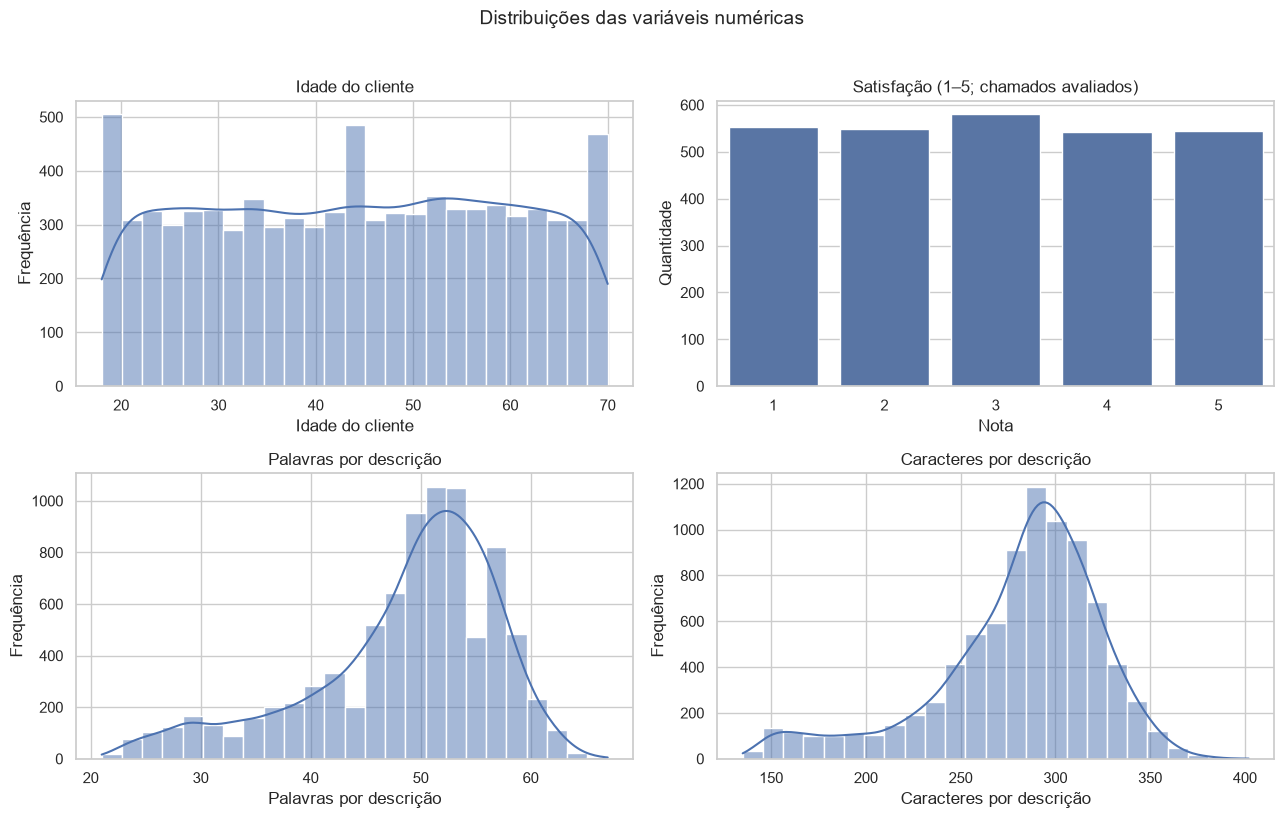

,count,mean,std,min,median,max,skew
customer_age,8469.0,44.03,15.30,18.0,44.0,70.0,-0.02
customer_satisfaction_rating,2769.0,2.99,1.41,1.0,3.0,5.0,0.01
text_word_count,8469.0,48.54,8.62,21.0,51.0,67.0,-0.99
text_char_count,8469.0,280.66,44.07,135.0,289.0,402.0,-1.03


In [10]:
num_cols = ["customer_age", "customer_satisfaction_rating", "text_word_count", "text_char_count"]
num_labels = {
    "customer_age": "Idade do cliente",
    "customer_satisfaction_rating": "Satisfação (1–5; chamados avaliados)",
    "text_word_count": "Palavras por descrição",
    "text_char_count": "Caracteres por descrição",
}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), num_cols):
    series = dados[col].dropna()
    if col == "customer_satisfaction_rating":
        sns.countplot(x=series.astype(int), color=sns.color_palette()[0], ax=ax)
        ax.set_xlabel("Nota")
        ax.set_ylabel("Quantidade")
    else:
        sns.histplot(x=series, bins=25, kde=True, color=sns.color_palette()[0], ax=ax)
        ax.set_xlabel(num_labels[col])
        ax.set_ylabel("Frequência")
    ax.set_title(num_labels[col])
fig.suptitle("Distribuições das variáveis numéricas", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

display(dados[num_cols].agg(["count", "mean", "std", "min", "median", "max", "skew"]).T.round(2))

### Variáveis categóricas

Os gráficos a seguir mostram as distribuições de tipo, prioridade, status e canal, seguidos dos assuntos e produtos mais frequentes. Frequências próximas entre classes podem refletir a forma como os dados sintéticos foram construídos e não necessariamente o volume de demanda em uma operação real.

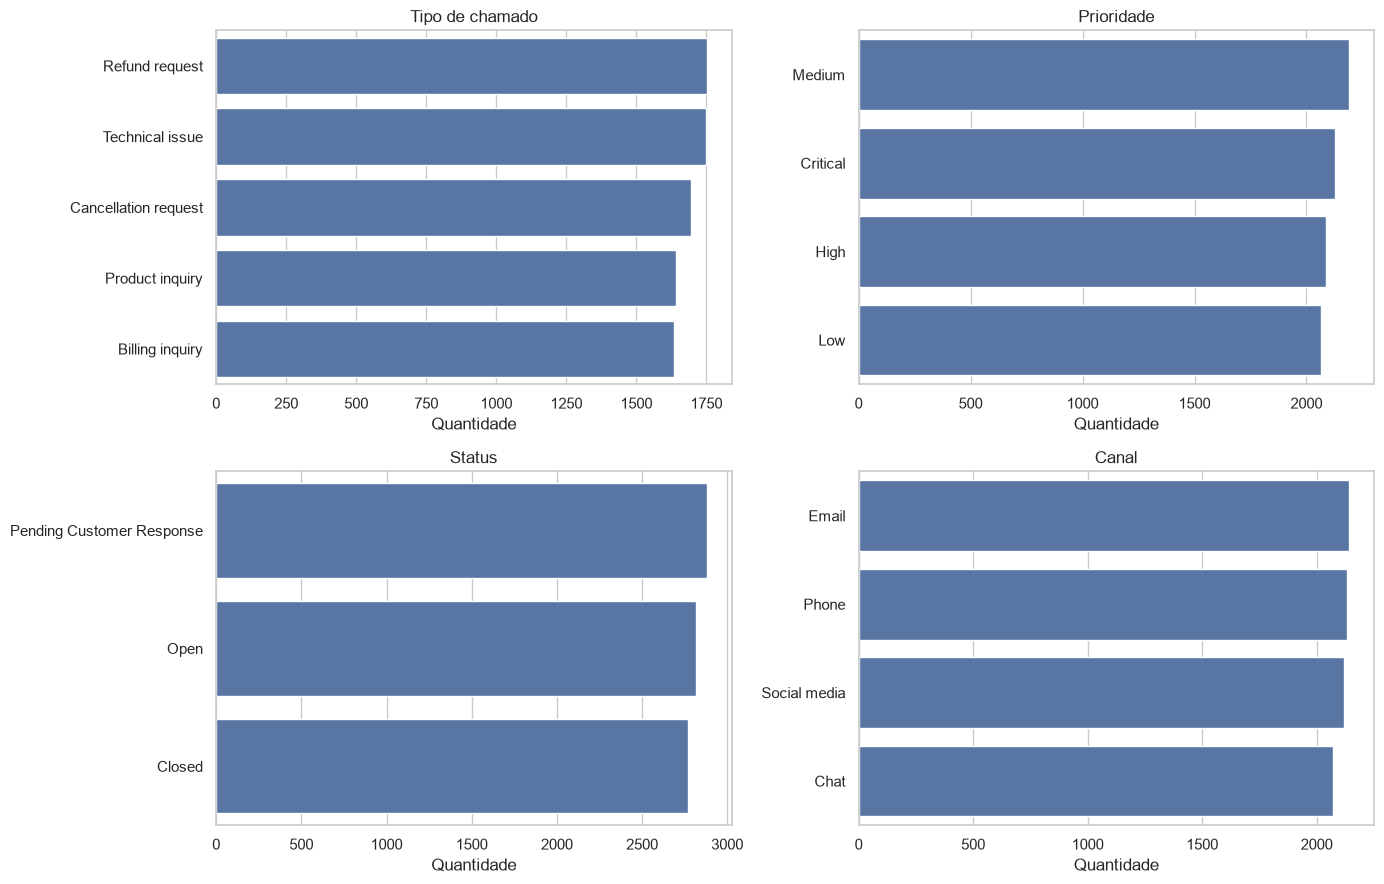

In [11]:
plot_cols = ["ticket_type", "ticket_priority", "ticket_status", "ticket_channel"]
plot_titles = ["Tipo de chamado", "Prioridade", "Status", "Canal"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col, title in zip(axes.ravel(), plot_cols, plot_titles):
    order = dados[col].value_counts().index
    sns.countplot(data=dados, y=col, order=order, color=sns.color_palette()[0], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Quantidade")
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

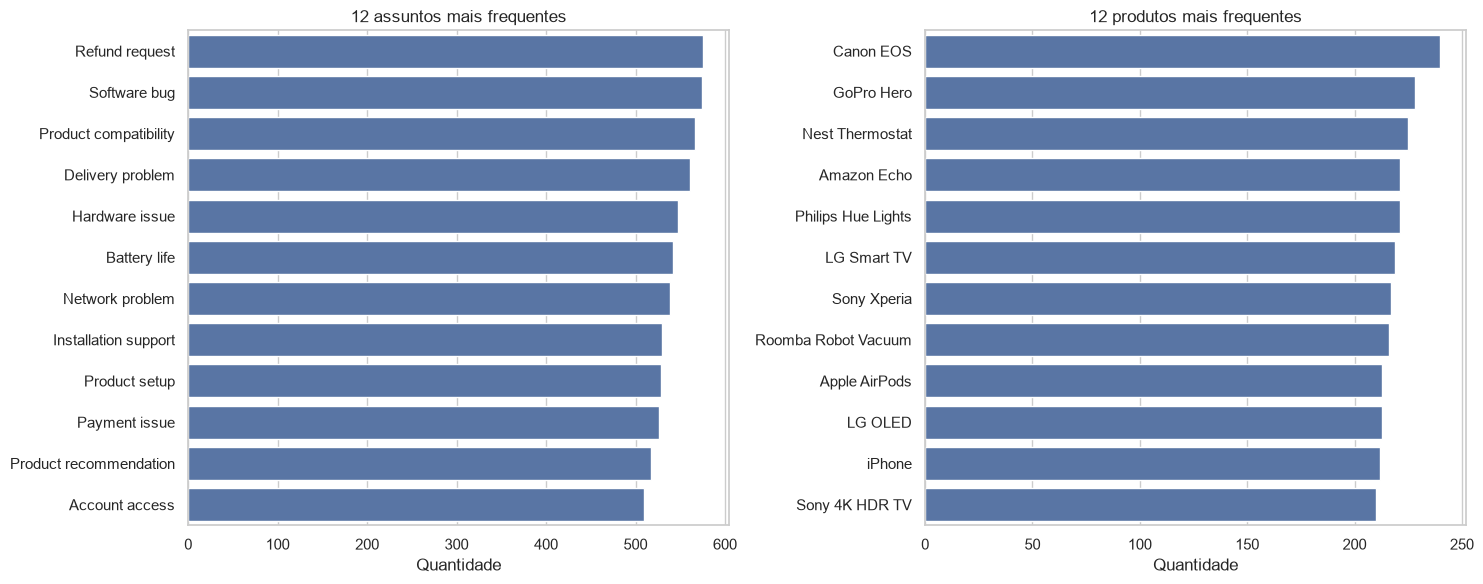

Distribuição percentual dos tipos de chamado (%):


,percentual
ticket_type,
Refund request,20.69
Technical issue,20.63
Cancellation request,20.01
Product inquiry,19.38
Billing inquiry,19.29


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
subject_order = dados["ticket_subject"].value_counts().head(12).index
product_order = dados["product_purchased"].value_counts().head(12).index
sns.countplot(data=dados[dados["ticket_subject"].isin(subject_order)], y="ticket_subject", order=subject_order, color=sns.color_palette()[0], ax=axes[0])
sns.countplot(data=dados[dados["product_purchased"].isin(product_order)], y="product_purchased", order=product_order, color=sns.color_palette()[0], ax=axes[1])
axes[0].set_title("12 assuntos mais frequentes")
axes[0].set_xlabel("Quantidade"); axes[0].set_ylabel("")
axes[1].set_title("12 produtos mais frequentes")
axes[1].set_xlabel("Quantidade"); axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

print("Distribuição percentual dos tipos de chamado (%):")
display((dados["ticket_type"].value_counts(normalize=True).mul(100).round(2)).rename("percentual").to_frame())

### Variáveis textuais

A descrição livre será analisada por comprimento e frequência lexical. Como existe texto de template, incluindo marcadores como `{product_purchased}` e outros campos entre chaves, o cálculo de frequência remove esses marcadores restantes. Uma lista enxuta de palavras funcionais em inglês reduz, mas não elimina, o peso de frases padronizadas.

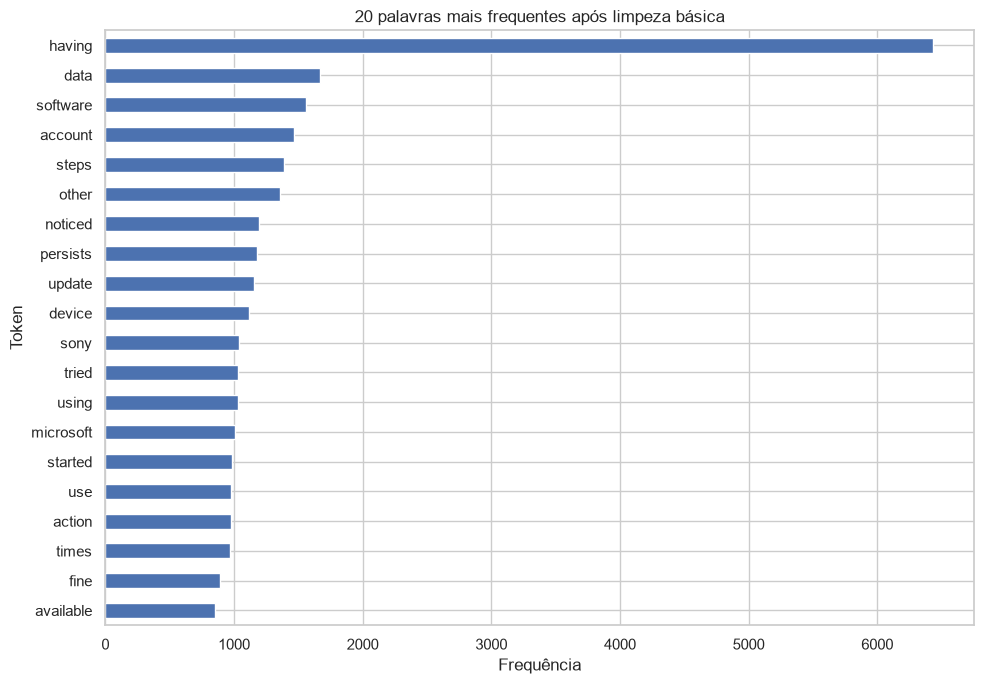

Mediana de palavras por descrição: 51
Média de palavras por descrição: 48.54
Percentual com marcador adicional de template: 9.6%


In [13]:
english_stopwords = set("""a an the and or but if then than so because while for to of in on at by with from into about as is am are was were be been being do does did have has had it its this that these those i you he she we they me my your our their them us please assist help support issue problem customer product purchased need want unable unable resolve working works work not no yes can could would should will just also very more most some any all there here when where why how what which who whom""".split())
tokens = [token for text in text_for_tokens.dropna() for token in text.split() if token not in english_stopwords and len(token) > 2]
top_tokens = pd.Series(tokens).value_counts().head(20).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
top_tokens.plot(kind="barh", ax=ax)
ax.set_title("20 palavras mais frequentes após limpeza básica")
ax.set_xlabel("Frequência")
ax.set_ylabel("Token")
plt.tight_layout()
plt.show()

print(f"Mediana de palavras por descrição: {dados['text_word_count'].median():.0f}")
print(f"Média de palavras por descrição: {dados['text_word_count'].mean():.2f}")
print(f"Percentual com marcador adicional de template: {dados['has_unresolved_placeholder'].mean():.1%}")

## 1.6. Análise multivariada e testes de hipótese

Esta etapa examina relações entre variáveis numéricas e categóricas, e realiza os dois testes formais exigidos. Será adotado **α = 0,05** e o teste bilateral de Mann–Whitney U, uma escolha não paramétrica adequada para a nota ordinal e para comparar distribuições de comprimento textual sem pressupor normalidade.

Para cada hipótese:

- **H₀:** as distribuições dos dois grupos não diferem;
- **H₁:** as distribuições dos dois grupos diferem;
- **Regra:** rejeitar H₀ se *p* < 0,05; caso contrário, não rejeitar H₀.

O tamanho de efeito rank-biserial será apresentado como medida descritiva da separação entre os grupos. A direção depende da ordem dos grupos explicitada na tabela.

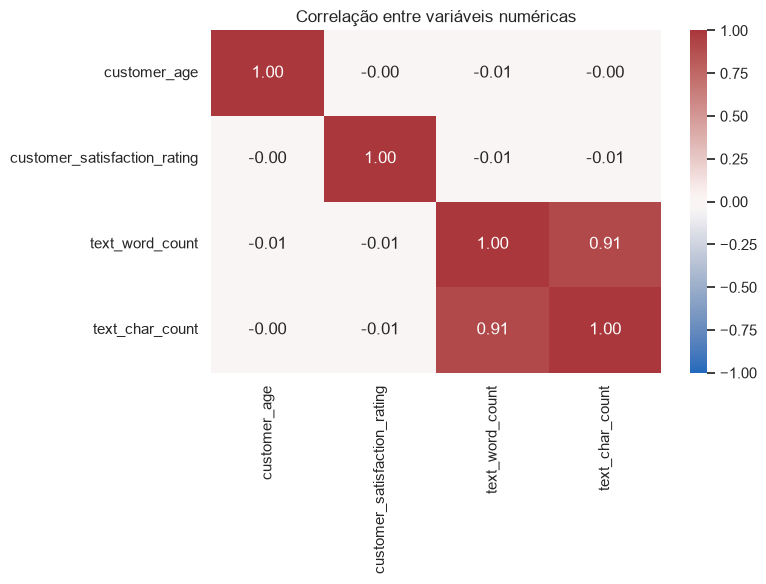

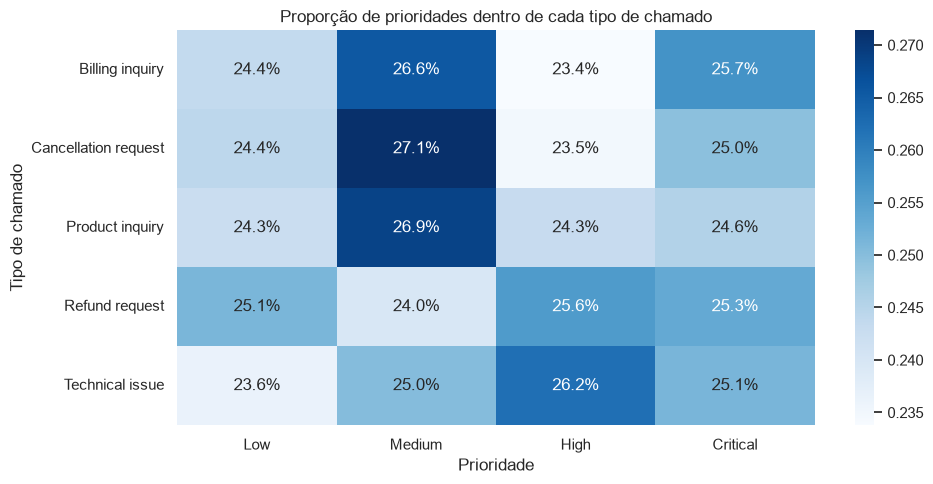

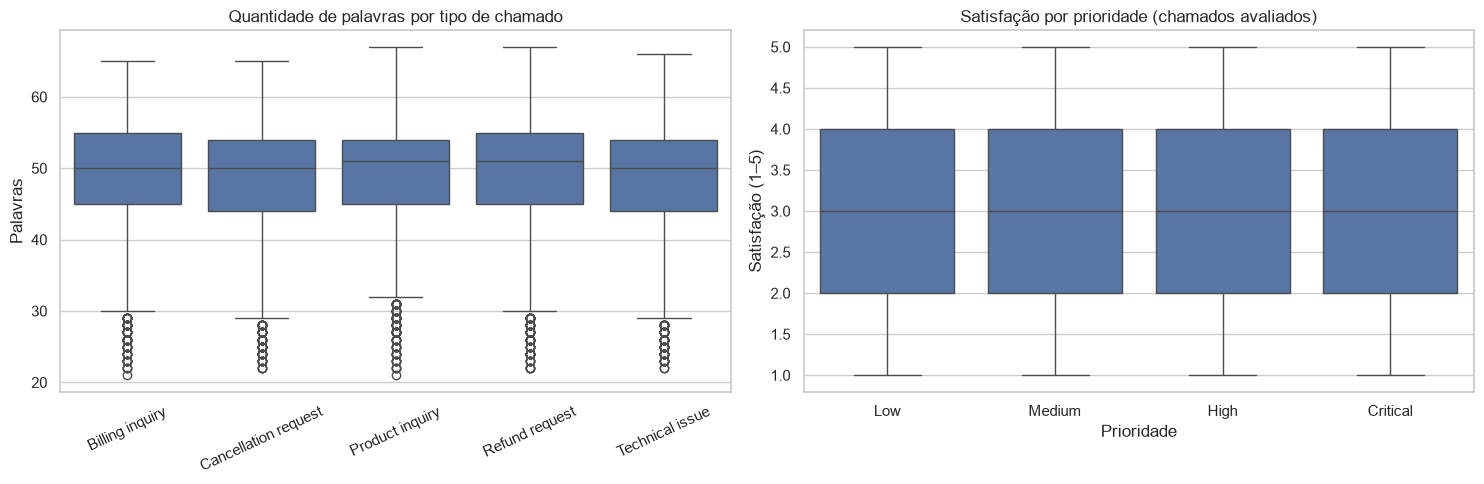

In [14]:
# Matriz de correlação de Pearson para variáveis numéricas; interpretação cautelosa para satisfação ordinal.
corr_cols = ["customer_age", "customer_satisfaction_rating", "text_word_count", "text_char_count"]
corr = dados[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

# Distribuição de prioridades dentro de cada tipo de chamado.
priority_order = [x for x in ["Low", "Medium", "High", "Critical"] if x in dados["ticket_priority"].astype(str).unique()]
type_priority = pd.crosstab(dados["ticket_type"], dados["ticket_priority"], normalize="index")
type_priority = type_priority.reindex(columns=priority_order)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(type_priority, annot=True, fmt=".1%", cmap="Blues", ax=ax)
ax.set_title("Proporção de prioridades dentro de cada tipo de chamado")
ax.set_xlabel("Prioridade")
ax.set_ylabel("Tipo de chamado")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=dados, x="ticket_type", y="text_word_count", ax=axes[0])
axes[0].set_title("Quantidade de palavras por tipo de chamado")
axes[0].set_xlabel(""); axes[0].set_ylabel("Palavras")
axes[0].tick_params(axis="x", rotation=25)
closed_ratings = dados[dados["customer_satisfaction_rating"].notna()]
sns.boxplot(data=closed_ratings, x="ticket_priority", y="customer_satisfaction_rating", order=priority_order, ax=axes[1])
axes[1].set_title("Satisfação por prioridade (chamados avaliados)")
axes[1].set_xlabel("Prioridade"); axes[1].set_ylabel("Satisfação (1–5)")
plt.tight_layout()
plt.show()

In [15]:
ALPHA = 0.05

# Hipótese 1: satisfação de chamados de prioridade Alta/Crítica vs. Baixa/Média.
# A nota só existe para chamados fechados, portanto o teste é restrito a esse subconjunto.
closed_ratings = dados[dados["customer_satisfaction_rating"].notna()].copy()
group_h1_a = closed_ratings.loc[
    closed_ratings["ticket_priority"].astype(str).isin(["High", "Critical"]),
    "customer_satisfaction_rating"
].dropna()
group_h1_b = closed_ratings.loc[
    closed_ratings["ticket_priority"].astype(str).isin(["Low", "Medium"]),
    "customer_satisfaction_rating"
].dropna()
u1, p1 = mannwhitneyu(group_h1_a, group_h1_b, alternative="two-sided", method="auto")
rbc1 = (2 * u1 / (len(group_h1_a) * len(group_h1_b))) - 1

# Hipótese 2: comprimento textual de Technical issue vs. todos os outros tipos.
group_h2_a = dados.loc[dados["ticket_type"].astype(str).eq("Technical issue"), "text_word_count"].dropna()
group_h2_b = dados.loc[~dados["ticket_type"].astype(str).eq("Technical issue"), "text_word_count"].dropna()
u2, p2 = mannwhitneyu(group_h2_a, group_h2_b, alternative="two-sided", method="auto")
rbc2 = (2 * u2 / (len(group_h2_a) * len(group_h2_b))) - 1

hypothesis_results = pd.DataFrame([
    {
        "hipótese": "H1 — Satisfação por grupo de prioridade",
        "grupos_comparados": "High/Critical vs. Low/Medium (somente chamados com nota)",
        "n_grupo_1": len(group_h1_a), "n_grupo_2": len(group_h1_b),
        "mediana_grupo_1": group_h1_a.median(), "mediana_grupo_2": group_h1_b.median(),
        "U_Mann_Whitney": u1, "p_valor": p1, "rank_biserial": rbc1,
    },
    {
        "hipótese": "H2 — Comprimento do texto por tipo",
        "grupos_comparados": "Technical issue vs. demais tipos",
        "n_grupo_1": len(group_h2_a), "n_grupo_2": len(group_h2_b),
        "mediana_grupo_1": group_h2_a.median(), "mediana_grupo_2": group_h2_b.median(),
        "U_Mann_Whitney": u2, "p_valor": p2, "rank_biserial": rbc2,
    },
])
hypothesis_results["decisao_a_5%"] = np.where(hypothesis_results["p_valor"] < ALPHA, "Rejeitar H₀", "Não rejeitar H₀")
display(hypothesis_results.round({"mediana_grupo_1": 2, "mediana_grupo_2": 2, "U_Mann_Whitney": 2, "p_valor": 4, "rank_biserial": 4}))

,hipótese,grupos_comparados,n_grupo_1,n_grupo_2,mediana_grupo_1,mediana_grupo_2,U_Mann_Whitney,p_valor,rank_biserial,decisao_a_5%
0,H1 — Satisfação por grupo de prioridade,High/Critical vs. Low/Medium (somente chamados com nota),1431,1338,3.0,3.0,940665.0,0.4182,-0.0174,Não rejeitar H₀
1,H2 — Comprimento do texto por tipo,Technical issue vs. demais tipos,1747,6722,50.0,51.0,5776781.5,0.2968,-0.0162,Não rejeitar H₀


### Hipóteses estatísticas

**H1 — A satisfação difere entre prioridades altas/críticas e baixas/médias.**

- H₀: as distribuições de satisfação são iguais entre os grupos de prioridade.
- H₁: as distribuições de satisfação diferem entre os grupos.
- População analisada: apenas chamados com nota de satisfação disponível (nulos estruturais não foram imputados).

**H2 — O comprimento das descrições difere entre chamados técnicos e os demais tipos.**

- H₀: as distribuições do número de palavras são iguais nos dois grupos.
- H₁: as distribuições do número de palavras diferem.
- O comprimento é calculado após substituir o marcador principal `{product_purchased}` pelo produto associado e normalizar espaços; outros marcadores de template ainda podem existir.

O teste de Mann–Whitney compara as distribuições por postos. Quando as formas das distribuições diferem, seu resultado não deve ser interpretado exclusivamente como teste de medianas.

In [16]:
for _, row in hypothesis_results.iterrows():
    print(row["hipótese"])
    print(f"  Grupos: {row['grupos_comparados']}")
    print(f"  n: {row['n_grupo_1']} vs. {row['n_grupo_2']}")
    print(f"  Medianas: {row['mediana_grupo_1']:.1f} vs. {row['mediana_grupo_2']:.1f}")
    print(f"  U={row['U_Mann_Whitney']:.0f}; p={row['p_valor']:.4f}; rank-biserial={row['rank_biserial']:.4f}")
    print(f"  Decisão (α={ALPHA}): {row['decisao_a_5%']}\n")

H1 — Satisfação por grupo de prioridade
  Grupos: High/Critical vs. Low/Medium (somente chamados com nota)
  n: 1431 vs. 1338
  Medianas: 3.0 vs. 3.0
  U=940665; p=0.4182; rank-biserial=-0.0174
  Decisão (α=0.05): Não rejeitar H₀

H2 — Comprimento do texto por tipo
  Grupos: Technical issue vs. demais tipos
  n: 1747 vs. 6722
  Medianas: 50.0 vs. 51.0
  U=5776782; p=0.2968; rank-biserial=-0.0162
  Decisão (α=0.05): Não rejeitar H₀



## 1.7. Identificação de outliers e anomalias

O critério do intervalo interquartil (IQR) será aplicado à idade, à quantidade de palavras e à quantidade de caracteres. A nota de satisfação não será classificada como outlier pelo IQR: é uma escala ordinal limitada de 1 a 5, na qual as notas extremas são valores válidos.

Além dos outliers estatísticos, serão destacadas anomalias semânticas identificadas na verificação de qualidade: timestamps com semântica incompatível, sequência temporal invertida e marcadores de template residuais.

,variavel,Q1,Q3,IQR,limite_inferior,limite_superior,outliers_IQR,percentual_outliers
0,customer_age,31.0,57.0,26.0,-8.0,96.0,0,0.00
1,text_word_count,45.0,55.0,10.0,30.0,70.0,417,4.92
2,text_char_count,261.0,309.0,48.0,189.0,381.0,488,5.76


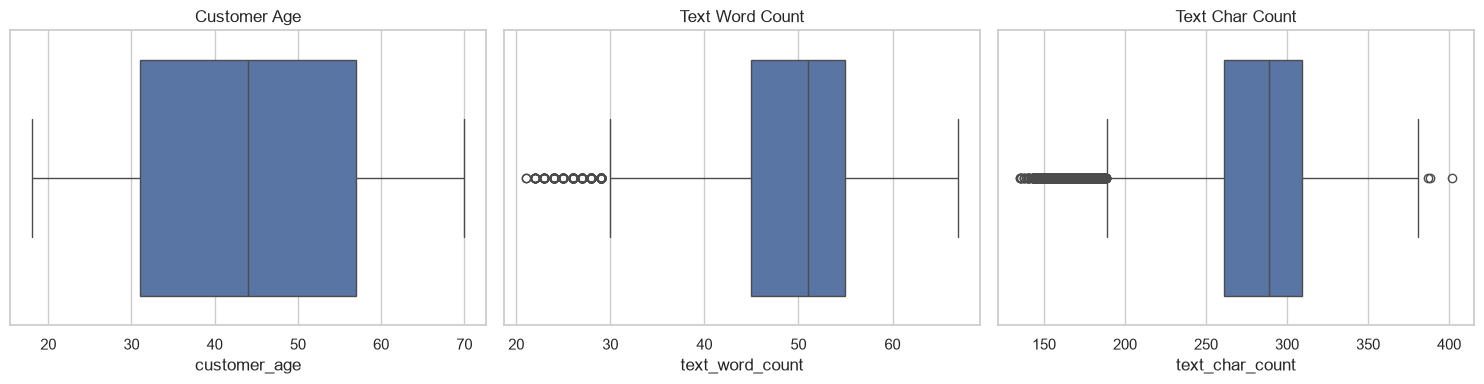

In [17]:
outlier_cols = ["customer_age", "text_word_count", "text_char_count"]
outlier_rows = []
for col in outlier_cols:
    values = dados[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (values < lower) | (values > upper)
    outlier_rows.append({
        "variavel": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "limite_inferior": lower,
        "limite_superior": upper,
        "outliers_IQR": int(mask.sum()),
        "percentual_outliers": float(mask.mean() * 100),
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(x=dados[col], ax=ax)
    ax.set_title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

In [18]:
anomalies = pd.DataFrame([
    {"anomalia": "Ausência estrutural de resposta inicial", "evidência": f"{raw['First Response Time'].isna().sum():,} registros; todos associados ao status Open"},
    {"anomalia": "Resolução/nota ausentes em chamados não fechados", "evidência": f"{raw['Time to Resolution'].isna().sum():,} tempos, {raw['Resolution'].isna().sum():,} resoluções e {raw['Customer Satisfaction Rating'].isna().sum():,} notas ausentes"},
    {"anomalia": "Timestamps concentrados em janela de 2023", "evidência": f"primeira resposta: {first_response_dt.min()} a {first_response_dt.max()}"},
    {"anomalia": "Resolução anterior à primeira resposta", "evidência": f"{chronology_issue.sum():,}/{len(closed):,} chamados fechados ({chronology_issue.mean():.1%})"},
    {"anomalia": "Marcadores de template residuais", "evidência": f"{dados['has_unresolved_placeholder'].sum():,} descrições após substituição do marcador principal"},
])
display(anomalies)

,anomalia,evidência
0,Ausência estrutural de resposta inicial,"2,819 registros; todos associados ao status Open"
1,Resolução/nota ausentes em chamados não fechados,"5,700 tempos, 5,700 resoluções e 5,700 notas ausentes"
2,Timestamps concentrados em janela de 2023,primeira resposta: 2023-05-31 21:55:39 a 2023-06-02 00:54:21
3,Resolução anterior à primeira resposta,"1,365/2,769 chamados fechados (49.3%)"
4,Marcadores de template residuais,816 descrições após substituição do marcador principal


## 1.8. Documentação do EDA e conclusões

### Síntese dos achados

As conclusões abaixo são produzidas a partir dos resultados exibidos nas células anteriores. Elas descrevem este arquivo e não devem ser generalizadas sem validação externa, pois a fonte é sintética.

In [19]:
# Métricas resumidas geradas a partir do dataset carregado.
status_pct = (raw["Ticket Status"].value_counts(normalize=True) * 100).round(1)
type_pct = (raw["Ticket Type"].value_counts(normalize=True) * 100).round(1)
print(f"1. Dataset: {raw.shape[0]:,} registros e {raw.shape[1]} colunas.")
print(f"2. Idade dos clientes: {raw['Customer Age'].min()}–{raw['Customer Age'].max()} anos; média={raw['Customer Age'].mean():.1f}, mediana={raw['Customer Age'].median():.1f}.")
print(f"3. Texto: mediana={dados['text_word_count'].median():.0f} palavras; mediana={dados['text_char_count'].median():.0f} caracteres.")
print(f"4. Chamados fechados: {(raw['Ticket Status'].eq('Closed').mean() * 100):.1f}% do conjunto.")
print(f"5. Notas de satisfação: n={raw['Customer Satisfaction Rating'].notna().sum():,}; média={raw['Customer Satisfaction Rating'].mean():.2f}, mediana={raw['Customer Satisfaction Rating'].median():.1f}.")
print(f"6. Duplicatas completas: {raw.duplicated().sum()}; Ticket IDs duplicados: {raw['Ticket ID'].duplicated().sum()}.")
print(f"7. Tipo de chamado mais frequente: {type_pct.index[0]} ({type_pct.iloc[0]:.1f}%).")
print("\nResultados dos testes:")
for row in hypothesis_results.itertuples(index=False):
    conclusao = "há evidência de diferença estatística" if row.p_valor < ALPHA else "não há evidência suficiente de diferença estatística"
    print(f"- {row.hipótese}: p={row.p_valor:.4f}; {conclusao} a α={ALPHA:.2f}.")

1. Dataset: 8,469 registros e 17 colunas.
2. Idade dos clientes: 18–70 anos; média=44.0, mediana=44.0.
3. Texto: mediana=51 palavras; mediana=289 caracteres.
4. Chamados fechados: 32.7% do conjunto.
5. Notas de satisfação: n=2,769; média=2.99, mediana=3.0.
6. Duplicatas completas: 0; Ticket IDs duplicados: 0.
7. Tipo de chamado mais frequente: Refund request (20.7%).

Resultados dos testes:
- H1 — Satisfação por grupo de prioridade: p=0.4182; não há evidência suficiente de diferença estatística a α=0.05.
- H2 — Comprimento do texto por tipo: p=0.2968; não há evidência suficiente de diferença estatística a α=0.05.


### Conclusões e decisões para etapas futuras

1. **Ausência de dados:** a falta de resolução, tempo de resolução e satisfação acompanha o status do chamado. Manter esses nulos como informação do ciclo de vida é mais correto do que imputar valores artificiais.
2. **Integridade temporal:** os timestamps de resposta e resolução não representam uma duração confiável neste arquivo. A inversão temporal em aproximadamente metade dos chamados fechados reforça a decisão de excluí-los das análises inferenciais; usar tais campos exigiria corrigir a fonte ou documentar uma regra de reconstrução validada.
3. **Texto parcialmente padronizado:** os comprimentos se concentram em uma faixa relativamente estreita. A presença de marcadores entre chaves indica template não totalmente renderizado e pode prejudicar a modelagem textual se não for normalizada.
4. **Classes quase equilibradas:** verificar as frequências de `Ticket Type` antes da modelagem ajuda a definir uma baseline; o equilíbrio de classes não garante que o texto contenha sinal discriminativo.
5. **Hipóteses:** interpretar cada teste pela decisão mostrada na tabela. Um *p*-valor acima de 0,05 não comprova igualdade entre grupos; indica apenas que, com esses dados e esse teste, não foi encontrada evidência suficiente para rejeitar H₀.
6. **Limite externo:** por ser um conjunto sintético, os padrões e a ausência de associações podem refletir o mecanismo de geração dos dados, e não o comportamento de clientes reais.

### Reprodutibilidade e fonte

- **Arquivo utilizado:** `data/customer_support_tickets.csv`.
- **Notebook original preservado:** `eda/eda_customer_support_tickets.ipynb`.
- **Este notebook TP2:** `eda/eda_TP2.ipynb`.
- **Fonte registrada na documentação do projeto:** Kaggle — *Customer Support Ticket Dataset*, por Suraj Jha; licença CC0 1.0; dataset descrito como sintético.
- **Bibliotecas:** pandas, NumPy, Matplotlib, Seaborn e SciPy.

Para reproduzir: instale as bibliotecas acima, abra o notebook no Jupyter/VS Code e execute **Run All**. O caminho do CSV é resolvido a partir da raiz do projeto ou da pasta `eda/`.